# 01 · Data Exploration & Preprocessing — Obesity Risk Levels

Follows the course **Preprocessing_Reference.ipynb** rule:
**fit on the training rows only, then transform training, test, and any future row the same way.**

| Step | What happens | Learns anything from data? |
|---|---|---|
| 0 | Load, basic cleaning, drop exact duplicates | No |
| 1 | Stratified 70/15/15 train/validation/test split | No |
| 2 | Explore the **training** rows | No |
| 3 | Build the preprocessor (fill → scale / encode) | Yes, training rows only |
| 4 | Transform all three sets, check, save for notebooks 02 and 03 | No (reuses step 3) |

## Setup

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

RANDOM_STATE = 42      # everyone on the team uses this seed

## Step 0. Basic data cleaning

Counting rows, blanks, and duplicates is fine on the whole table. We are only looking, not learning a value that changes the data.

In [2]:
DATA_PATH = "../data/11_obesity_risk_levels_train.csv"
TARGET = "NObeyesdad"

rawData = pd.read_csv(DATA_PATH)
print("Original dataset:", rawData.shape)
rawData.columns = rawData.columns.str.strip()          # strip whitespace from column names

# An id column is just a row number. It carries no information.
if "id" in rawData.columns:
    rawData = rawData.drop(columns="id")

rawData.info()
print()
print("Missing values per column:")
blanks = rawData.isnull().sum()
print(blanks[blanks > 0] if blanks.any() else "none")

Original dataset: (1794, 17)
<class 'pandas.DataFrame'>
RangeIndex: 1794 entries, 0 to 1793
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Gender                          1794 non-null   str    
 1   Age                             1794 non-null   float64
 2   Height                          1794 non-null   float64
 3   Weight                          1794 non-null   float64
 4   family_history_with_overweight  1794 non-null   str    
 5   FAVC                            1794 non-null   str    
 6   FCVC                            1794 non-null   float64
 7   NCP                             1794 non-null   float64
 8   CAEC                            1794 non-null   str    
 9   SMOKE                           1794 non-null   str    
 10  CH2O                            1794 non-null   float64
 11  SCC                             1794 non-null   str    
 12  FAF             

In [3]:
categorical_cols = ["Gender", "family_history_with_overweight", "FAVC", "CAEC",
                    "SMOKE", "SCC", "CALC", "MTRANS"]

# Fix inconsistent text formatting (extra spaces)
for col in categorical_cols:
    rawData[col] = rawData[col].apply(lambda x: x.strip() if isinstance(x, str) else x)

# Impossible values become blanks; the preprocessor fills them later from training rows
for col in ["Age", "Height", "Weight"]:
    bad = rawData[col] <= 0
    print(f"{col}: {int(bad.sum())} values <= 0")
    rawData.loc[bad, col] = np.nan

# Rows without a target label cannot be used
rawData = rawData.dropna(subset=[TARGET])

Age: 0 values <= 0
Height: 0 values <= 0
Weight: 0 values <= 0


In [4]:
dups = rawData.duplicated(keep="first")
print("exact duplicate rows:", int(dups.sum()))
rawData[rawData.duplicated(keep=False)].sort_values(list(rawData.columns)).head(10)

exact duplicate rows: 20


,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
120,Female,18.0,1.62,55.0,yes,yes,2.0,3.0,Frequently,no,1.0,no,1.0,1.0,no,Public_Transportation,Normal_Weight
704,Female,18.0,1.62,55.0,yes,yes,2.0,3.0,Frequently,no,1.0,no,1.0,1.0,no,Public_Transportation,Normal_Weight
507,Female,21.0,1.52,42.0,no,no,3.0,1.0,Frequently,no,1.0,no,0.0,0.0,Sometimes,Public_Transportation,Insufficient_Weight
777,Female,21.0,1.52,42.0,no,no,3.0,1.0,Frequently,no,1.0,no,0.0,0.0,Sometimes,Public_Transportation,Insufficient_Weight
198,Female,21.0,1.52,42.0,no,yes,3.0,1.0,Frequently,no,1.0,no,0.0,0.0,Sometimes,Public_Transportation,Insufficient_Weight
429,Female,21.0,1.52,42.0,no,yes,3.0,1.0,Frequently,no,1.0,no,0.0,0.0,Sometimes,Public_Transportation,Insufficient_Weight
1291,Female,21.0,1.52,42.0,no,yes,3.0,1.0,Frequently,no,1.0,no,0.0,0.0,Sometimes,Public_Transportation,Insufficient_Weight
1436,Female,22.0,1.69,65.0,yes,yes,2.0,3.0,Sometimes,no,2.0,no,1.0,1.0,Sometimes,Public_Transportation,Normal_Weight
1600,Female,22.0,1.69,65.0,yes,yes,2.0,3.0,Sometimes,no,2.0,no,1.0,1.0,Sometimes,Public_Transportation,Normal_Weight
671,Male,18.0,1.72,53.0,yes,yes,2.0,3.0,Sometimes,no,2.0,no,0.0,2.0,Sometimes,Public_Transportation,Insufficient_Weight


**Decision: drop exact duplicates, before the split.**

- If one copy lands in training and another in test, the model is tested on a row it already memorized. That inflates the test score.
- Dropping duplicates does not learn anything from the data, so doing it before the split does not leak.
- The number removed is small next to the size of the dataset, so we lose almost nothing.

In [5]:
before = len(rawData)
df = rawData.drop_duplicates(keep="first").reset_index(drop=True)
print(f"rows before: {before}   removed: {before - len(df)}   rows after: {len(df)}")

os.makedirs("../data", exist_ok=True)
df.to_csv("../data/obesity_cleaned.csv", index=False)
print("Cleaned data saved to ../data/obesity_cleaned.csv")

rows before: 1794   removed: 20   rows after: 1774
Cleaned data saved to ../data/obesity_cleaned.csv


## Column groups

In [6]:
# Measurements and 1-3 / 0-3 survey scales (stored as decimals in this dataset)
numeric = ["Age", "Height", "Weight", "FCVC", "NCP", "CH2O", "FAF", "TUE"]

# Two possible values each
binary = ["Gender", "family_history_with_overweight", "FAVC", "SMOKE", "SCC"]

# Categories with a real order: no < Sometimes < Frequently < Always
ordinal = ["CAEC", "CALC"]
ordinal_order = [["no", "Sometimes", "Frequently", "Always"]] * len(ordinal)

# Categories with no order
nominal = ["MTRANS"]

all_features = numeric + binary + ordinal + nominal
missing = set(all_features + [TARGET]) - set(df.columns)
extra = set(df.columns) - set(all_features + [TARGET])
print("columns missing from the file:", missing or "none")
print("columns in the file not used:", extra or "none")

for c in ordinal:
    unexpected = set(df[c].dropna().unique()) - set(ordinal_order[0])
    if unexpected:
        print(f"{c} has values not in the order list: {unexpected}")

columns missing from the file: none
columns in the file not used: none


### Target labels

The classes have a natural order by BMI. We store them as 0–6 in that order, and keep the mapping so plots and reports can show the names.

In [7]:
class_order = [
    "Insufficient_Weight", "Normal_Weight",
    "Overweight_Level_I", "Overweight_Level_II",
    "Obesity_Type_I", "Obesity_Type_II", "Obesity_Type_III",
]
unknown = set(df[TARGET].unique()) - set(class_order)
assert not unknown, f"target values not in class_order: {unknown}"

label_to_id = {name: i for i, name in enumerate(class_order)}
X = df[all_features]
y = df[TARGET].map(label_to_id).values

counts = pd.Series(df[TARGET]).value_counts().reindex(class_order)
print(counts.to_string())
print()
print("smallest class share:", round(counts.min() / counts.sum(), 3))

NObeyesdad
Insufficient_Weight    227
Normal_Weight          241
Overweight_Level_I     234
Overweight_Level_II    247
Obesity_Type_I         298
Obesity_Type_II        252
Obesity_Type_III       275

smallest class share: 0.128


## Step 1. Split first: 70% train, 15% validation, 15% test

Everything that learns from data comes after this cell. `stratify` keeps the share of each obesity class the same in all three sets.

- **Train**: fit the preprocessor and the models.
- **Validation**: compare models and tune settings (notebooks 02 and 03).
- **Test**: score the final model **once**, at the very end.

In [8]:
# 70% training, 30% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=RANDOM_STATE, stratify=y
)
# Split temporary data into 15% validation and 15% testing
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=RANDOM_STATE, stratify=y_temp
)
print("Training:  ", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:   ", X_test.shape)

share = pd.DataFrame({
    "all":   pd.Series(y).value_counts(normalize=True).sort_index(),
    "train": pd.Series(y_train).value_counts(normalize=True).sort_index(),
    "val":   pd.Series(y_val).value_counts(normalize=True).sort_index(),
    "test":  pd.Series(y_test).value_counts(normalize=True).sort_index(),
})
share.index = class_order
share.round(3)

Training:   (1241, 16)
Validation: (266, 16)
Testing:    (267, 16)


,all,train,val,test
Insufficient_Weight,0.128,0.128,0.128,0.127
Normal_Weight,0.136,0.136,0.135,0.135
Overweight_Level_I,0.132,0.132,0.132,0.131
Overweight_Level_II,0.139,0.139,0.139,0.139
Obesity_Type_I,0.168,0.168,0.169,0.169
Obesity_Type_II,0.142,0.142,0.143,0.142
Obesity_Type_III,0.155,0.155,0.154,0.157


## Step 2. Explore the training rows

From here on every plot uses **training rows only**. Validation and test rows stay hidden.

In [9]:
train = X_train.copy()
train["class"] = pd.Categorical([class_order[i] for i in y_train], categories=class_order, ordered=True)
train[numeric].describe().round(2)

,Age,Height,Weight,FCVC,NCP,CH2O,FAF,TUE
count,1241.00,1241.00,1241.00,1241.00,1241.00,1241.00,1241.00,1241.00
mean,24.27,1.70,86.62,2.40,2.69,1.99,1.01,0.69
std,6.25,0.09,26.00,0.53,0.76,0.60,0.85,0.62
min,14.00,1.48,39.37,1.00,1.00,1.00,0.00,0.00
25%,19.82,1.63,65.36,2.00,2.72,1.55,0.12,0.00
50%,22.87,1.70,83.15,2.32,3.00,2.00,1.00,0.69
75%,26.00,1.77,107.11,3.00,3.00,2.44,1.62,1.00
max,55.25,1.98,165.06,3.00,4.00,3.00,3.00,2.00


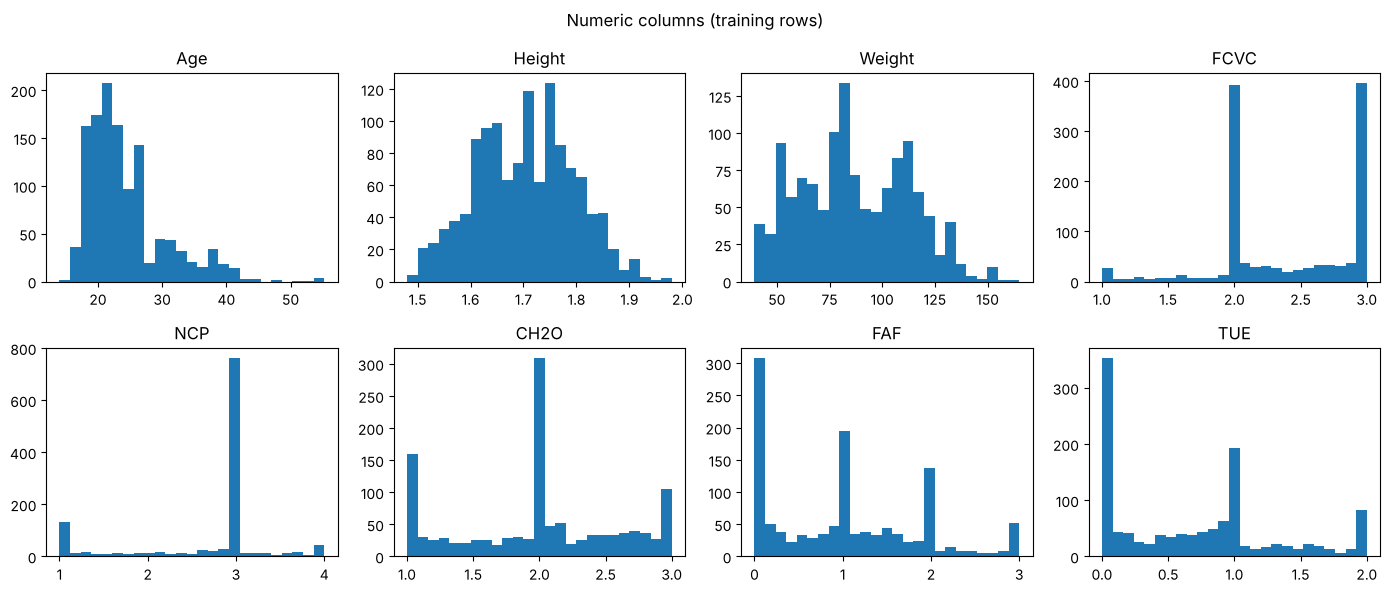

In [10]:
fig, axes = plt.subplots(2, 4, figsize=(14, 6))
for ax, c in zip(axes.flat, numeric):
    ax.hist(X_train[c].dropna(), bins=25)
    ax.set_title(c)
plt.suptitle("Numeric columns (training rows)")
plt.tight_layout()
plt.show()

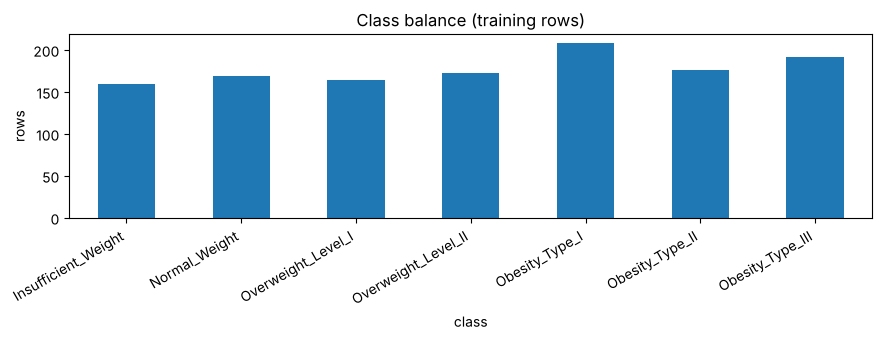

In [11]:
plt.figure(figsize=(9, 3.5))
train["class"].value_counts().reindex(class_order).plot(kind="bar")
plt.title("Class balance (training rows)")
plt.ylabel("rows")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

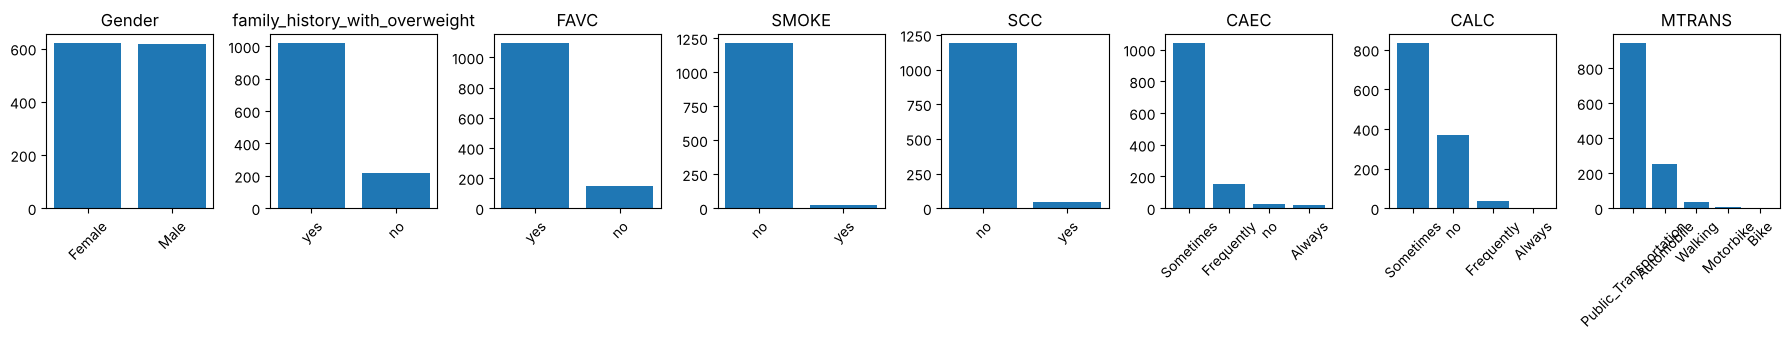

In [12]:
fig, axes = plt.subplots(1, len(binary + ordinal + nominal), figsize=(18, 3.5))
for ax, c in zip(axes, binary + ordinal + nominal):
    vc = X_train[c].value_counts()
    ax.bar(vc.index.astype(str), vc.values)
    ax.set_title(c)
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

### Outliers (IQR rule, training rows)

In [13]:
rows = []
for c in numeric:
    col = X_train[c]
    q1, q3 = col.quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    rows.append({"column": c, "low limit": lo, "high limit": hi,
                 "rows outside": int(((col < lo) | (col > hi)).sum())})
pd.DataFrame(rows).round(2)

,column,low limit,high limit,rows outside
0,Age,10.55,35.27,96
1,Height,1.42,1.98,0
2,Weight,2.75,169.72,0
3,FCVC,0.50,4.50,0
4,NCP,2.30,3.42,344
5,CH2O,0.22,3.77,0
6,FAF,-2.13,3.88,0
7,TUE,-1.50,2.50,0


An outlier is not automatically a mistake. Ages in the 50s or a weight of 170 kg are real people. **We keep these rows.**

### ⚠️ For the team: Height and Weight nearly define the target

The classes were labeled from BMI = Weight / Height². A model that gets Height and Weight can mostly rebuild BMI and score very high without learning anything about eating habits or activity.

The plot below shows how well BMI alone separates the classes. **Decide as a team** whether to keep Height and Weight, and say which you chose in the report. One option is to train both versions in notebook 02 and compare.

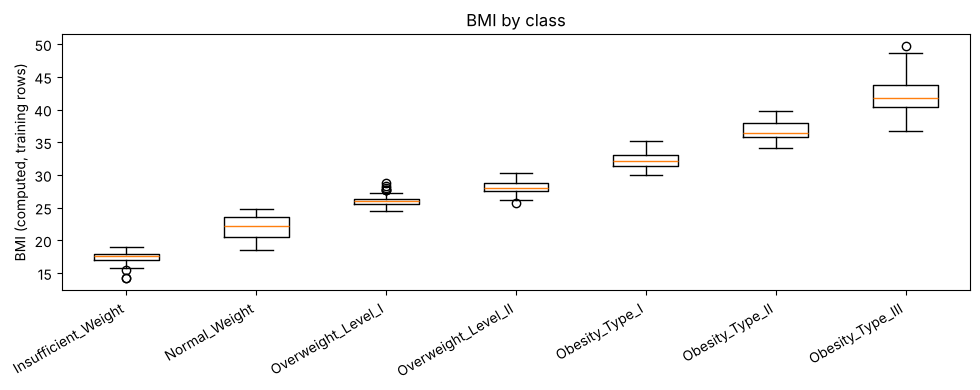

numeric columns used: ['Age', 'Height', 'Weight', 'FCVC', 'NCP', 'CH2O', 'FAF', 'TUE']


In [14]:
bmi = train["Weight"] / train["Height"] ** 2
plt.figure(figsize=(10, 4))
plt.boxplot([bmi[train["class"] == c] for c in class_order])
plt.xticks(range(1, len(class_order) + 1), class_order, rotation=30, ha="right")
plt.ylabel("BMI (computed, training rows)")
plt.title("BMI by class")
plt.tight_layout()
plt.show()

DROP_HEIGHT_WEIGHT = False   # set True if the team decides to exclude them
if DROP_HEIGHT_WEIGHT:
    numeric = [c for c in numeric if c not in ("Height", "Weight")]
    X_train = X_train.drop(columns=["Height", "Weight"])
    X_val = X_val.drop(columns=["Height", "Weight"])
    X_test = X_test.drop(columns=["Height", "Weight"])
print("numeric columns used:", numeric)

## Step 3. Build the preprocessor

| Group | Fill blanks with | Then |
|---|---|---|
| numeric | median | MinMax scale |
| binary | most frequent | one 0/1 column each (`drop="if_binary"`) |
| ordinal | most frequent | codes 0–3 in the real order, then scale |
| nominal | most frequent | one yes/no column per category (`handle_unknown="ignore"`) |

This dataset may have no blanks, but the fill steps stay in so a future row with a blank still gets a prediction.

In [15]:
preprocessor = ColumnTransformer([
    ("numeric", Pipeline([
        ("fill", SimpleImputer(strategy="median")),
        ("scale", MinMaxScaler()),
    ]), numeric),
    ("binary", Pipeline([
        ("fill", SimpleImputer(strategy="most_frequent")),
        ("encode", OneHotEncoder(drop="if_binary", handle_unknown="ignore", sparse_output=False)),
    ]), binary),
    ("ordinal", Pipeline([
        ("fill", SimpleImputer(strategy="most_frequent")),
        ("encode", OrdinalEncoder(categories=ordinal_order,
                                  handle_unknown="use_encoded_value", unknown_value=-1)),
        ("scale", MinMaxScaler()),
    ]), ordinal),
    ("nominal", Pipeline([
        ("fill", SimpleImputer(strategy="most_frequent")),
        ("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ]), nominal),
])

preprocessor.fit(X_train)                     # fit: training rows ONLY
feature_names = [n.split("__", 1)[1] for n in preprocessor.get_feature_names_out()]
print(len(all_features), "raw columns ->", len(feature_names), "model columns")
print(feature_names)

16 raw columns -> 20 model columns
['Age', 'Height', 'Weight', 'FCVC', 'NCP', 'CH2O', 'FAF', 'TUE', 'Gender_Male', 'family_history_with_overweight_yes', 'FAVC_yes', 'SMOKE_yes', 'SCC_yes', 'CAEC', 'CALC', 'MTRANS_Automobile', 'MTRANS_Bike', 'MTRANS_Motorbike', 'MTRANS_Public_Transportation', 'MTRANS_Walking']


## Step 4. Transform all three sets with the same fitted preprocessor

In [16]:
X_train_ready = pd.DataFrame(preprocessor.transform(X_train), columns=feature_names, index=X_train.index)
X_val_ready   = pd.DataFrame(preprocessor.transform(X_val),   columns=feature_names, index=X_val.index)
X_test_ready  = pd.DataFrame(preprocessor.transform(X_test),  columns=feature_names, index=X_test.index)

print("blanks left:", int(sum(d.isna().sum().sum() for d in (X_train_ready, X_val_ready, X_test_ready))))
print()
print("training rows after scaling (always 0 to 1):")
print(X_train_ready.agg(["min", "max"]).round(2).T.head(len(numeric)).to_string())
print()
print("test rows (may go a little past 0 or 1; that is fine, a future row can too):")
print(X_test_ready.agg(["min", "max"]).round(2).T.head(len(numeric)).to_string())

blanks left: 0

training rows after scaling (always 0 to 1):
        min  max
Age     0.0  1.0
Height  0.0  1.0
Weight  0.0  1.0
FCVC    0.0  1.0
NCP     0.0  1.0
CH2O    0.0  1.0
FAF     0.0  1.0
TUE     0.0  1.0

test rows (may go a little past 0 or 1; that is fine, a future row can too):
         min   max
Age     0.05  1.02
Height  0.02  0.93
Weight  0.02  0.97
FCVC    0.00  1.00
NCP     0.00  1.00
CH2O    0.00  1.00
FAF     0.00  1.00
TUE     0.00  1.00


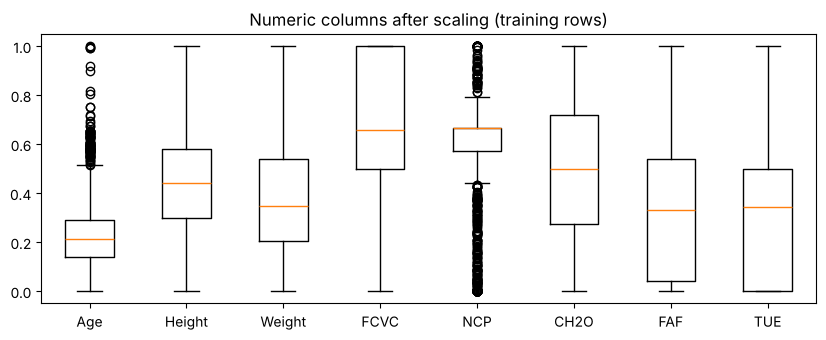

In [17]:
plt.figure(figsize=(10, 3.5))
plt.boxplot([X_train_ready[c] for c in numeric])
plt.xticks(range(1, len(numeric) + 1), numeric)
plt.title("Numeric columns after scaling (training rows)")
plt.show()

In [18]:
# Same row scored alone gives the same columns as in the batch (Step 5 check from the reference)
one = preprocessor.transform(X_test.iloc[[0]])
print("row alone matches batch:", bool(np.allclose(one[0], X_test_ready.iloc[0].values)))

row alone matches batch: True


## Save for notebooks 02 and 03

- `*_ready.csv`: model-ready features. `y_*.csv`: labels as 0–6.
- `*_raw.csv`: the same rows **before** preprocessing. The fairness audit needs readable `Gender` and `Age`.
- `preprocessor.joblib`: the fitted preprocessor, for new rows.
- `preprocessor_unfitted.joblib`: put this inside a `Pipeline` with each model for cross-validation in notebook 02, so every fold fits its own preprocessing.

In [19]:
from sklearn.base import clone

OUT = "../data/processed"
os.makedirs(OUT, exist_ok=True)

X_train_ready.to_csv(f"{OUT}/X_train_ready.csv", index=False)
X_val_ready.to_csv(f"{OUT}/X_val_ready.csv", index=False)
X_test_ready.to_csv(f"{OUT}/X_test_ready.csv", index=False)
pd.DataFrame({"y": y_train}).to_csv(f"{OUT}/y_train.csv", index=False)
pd.DataFrame({"y": y_val}).to_csv(f"{OUT}/y_val.csv", index=False)
pd.DataFrame({"y": y_test}).to_csv(f"{OUT}/y_test.csv", index=False)
X_train.to_csv(f"{OUT}/X_train_raw.csv", index=False)
X_val.to_csv(f"{OUT}/X_val_raw.csv", index=False)
X_test.to_csv(f"{OUT}/X_test_raw.csv", index=False)

joblib.dump(preprocessor, f"{OUT}/preprocessor.joblib")
joblib.dump(clone(preprocessor), f"{OUT}/preprocessor_unfitted.joblib")
joblib.dump({"class_order": class_order, "label_to_id": label_to_id,
             "feature_names": feature_names}, f"{OUT}/metadata.joblib")

print("saved to", OUT)
print(sorted(os.listdir(OUT)))

saved to ../data/processed
['X_test_raw.csv', 'X_test_ready.csv', 'X_train_raw.csv', 'X_train_ready.csv', 'X_val_raw.csv', 'X_val_ready.csv', 'metadata.joblib', 'preprocessor.joblib', 'preprocessor_unfitted.joblib', 'y_test.csv', 'y_train.csv', 'y_val.csv']


## Summary for the report

- Stripped extra spaces from text columns and turned impossible values (Age/Height/Weight ≤ 0) into blanks.
- Removed the exact duplicate rows before splitting, so no row appears in both training and test.
- Stratified 70/15/15 train/validation/test split, done before any step that learns from data.
- Fill values, scaling ranges, and encoder categories were learned from **training rows only** and reused for validation and test rows.
- `CAEC` and `CALC` encoded in their real order; `MTRANS` one-hot encoded; yes/no columns as single 0/1 columns.
- Outliers kept: they are plausible real people.
- Open team decision: keep or drop Height and Weight (they nearly define the label).